# Monte Carlo Experiments: Size, Power, and Robustness of Coverage Tests

Reproduces the simulation tables of the paper: Tables 1-8 and Figure 1.

**How to run.** Execute the notebook top to bottom in a fresh kernel (Kernel > Restart & Run All).
All random numbers come from one stream seeded with 42, so each cell depends on the cells above it.
Running cells out of order, or re-running a single cell, gives different draws.
Runtime is about 1-2 minutes on a laptop (set `FAST_RUN = True` for a quick smoke test).

Numbers are Monte Carlo estimates. Differences of a few tenths of a percentage point from the paper are
sampling noise; see the standard-error cell near the end for the size of that noise.

## 1. Setup & Core Functions

In [1]:
import time
import warnings

import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

plt.rcParams['figure.dpi'] = 110


/home/mykola/BTC_q_pred/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Constants

In [2]:
SEED = 42                # numpy.random.default_rng seed used throughout
H = 90                    # forecast horizon (days) used almost everywhere below
ALPHA = 0.20              # nominal miscoverage rate (80% nominal coverage)
REPS = 1000               # Monte Carlo replications, default across sections
T = 2000                  # evaluation-sample length (Tables 1-2)

FAST_RUN = False
FAST_FACTOR = 20


def effective_reps(reps: int) -> int:
    """Scale `reps` down by FAST_FACTOR when FAST_RUN is on."""
    if not FAST_RUN:
        return reps
    return max(1, reps // FAST_FACTOR)


print(f'H={H} ALPHA={ALPHA} REPS={REPS} T={T} FAST_RUN={FAST_RUN}')


H=90 ALPHA=0.2 REPS=1000 T=2000 FAST_RUN=False


### Coverage-test statistics

In [3]:
def kupiec_stat(V, alpha=0.20):
    """Kupiec (1995) unconditional coverage test; p-value per replication."""
    n = V.shape[1]
    V1 = V.sum(1)
    ph = np.clip(V1 / n, 1e-10, 1 - 1e-10)
    LR = -2 * (V1 * np.log(alpha / ph) + (n - V1) * np.log((1 - alpha) / (1 - ph)))
    return 1 - stats.chi2.cdf(np.where(V1 == 0, 0., LR), 1)


def _christ_components(V, alpha):
    """Shared LR-statistic computation behind christ_stat / christ_vec."""
    a, b = V[:, :-1], V[:, 1:]
    n00 = ((a == 0) & (b == 0)).sum(1)
    n01 = ((a == 0) & (b == 1)).sum(1)
    n10 = ((a == 1) & (b == 0)).sum(1)
    n11 = ((a == 1) & (b == 1)).sum(1)
    p01 = n01 / np.maximum(n00 + n01, 1)
    p11 = n11 / np.maximum(n10 + n11, 1)
    ph = (n01 + n11) / np.maximum(n00 + n01 + n10 + n11, 1)
    eps = 1e-300
    lnum = (n00 * np.log(np.clip(1 - p01, eps, 1)) + n01 * np.log(np.clip(p01, eps, 1))
            + n10 * np.log(np.clip(1 - p11, eps, 1)) + n11 * np.log(np.clip(p11, eps, 1)))
    lden = ((n00 + n10) * np.log(np.clip(1 - ph, eps, 1)) + (n01 + n11) * np.log(np.clip(ph, eps, 1)))
    n = V.shape[1]
    V1 = V.sum(1)
    phu = np.clip(V1 / n, 1e-10, 1 - 1e-10)
    LRu = -2 * (V1 * np.log(alpha / phu) + (n - V1) * np.log((1 - alpha) / (1 - phu)))
    LRc = np.where(V1 == 0, 0., LRu) + 2 * (lnum - lden)
    return LRc, p01, p11


def christ_stat(V, alpha=0.20):
    """Christoffersen (1998) conditional coverage test; p-value per replication."""
    LRc, _p01, _p11 = _christ_components(V, alpha)
    return 1 - stats.chi2.cdf(LRc, 2)


def christ_vec(V, alpha=0.20):
    """Like christ_stat, but also returns the fitted transition probabilities p01, p11."""
    LRc, p01, p11 = _christ_components(V, alpha)
    return 1 - stats.chi2.cdf(LRc, 2), p01, p11


def duration_test(V, alpha=0.20):
    """Simplified duration-based independence test: exponential vs Weibull likelihood ratio."""
    n_rep, n = V.shape
    pvals = np.full(n_rep, np.nan)
    for r in range(n_rep):
        v = V[r]
        idx = np.where(v == 1)[0]
        if len(idx) < 5:
            pvals[r] = 1.0
            continue
        durations = np.diff(idx).astype(float)
        durations = durations[durations > 0]
        if len(durations) < 5:
            pvals[r] = 1.0
            continue
        mean_d = durations.mean()
        ll_exp = -len(durations) * np.log(mean_d) - durations.sum() / mean_d
        logd = np.log(durations)

        def neg_ll(b):
            if b <= 0:
                return 1e10
            s_b = np.mean(durations ** b)
            ll = (len(durations) * np.log(b) - len(durations) * np.log(s_b)
                  + (b - 1) * logd.sum() - len(durations))
            return -ll

        bs = np.linspace(0.3, 3.0, 55)
        vals = [neg_ll(b) for b in bs]
        b_hat = bs[np.argmin(vals)]
        ll_weib = -neg_ll(b_hat)
        LR = max(-2 * (ll_exp - ll_weib), 0)
        pvals[r] = 1 - stats.chi2.cdf(LR, 1)
    return pvals


def hac_z(V, H, alpha=0.20, L=None):
    """HAC z-statistic for the violation rate (Bartlett kernel, lag L, default H-1)."""
    n = V.shape[1]
    if L is None:
        L = H - 1
    L = min(L, n - 2)
    Vc = V - V.mean(axis=1, keepdims=True)
    lrv = (Vc * Vc).mean(axis=1)
    for k in range(1, L + 1):
        w = 1 - k / (L + 1)
        lrv += 2 * w * (Vc[:, k:] * Vc[:, :-k]).sum(axis=1) / n
    lrv = np.maximum(lrv, 1e-12)
    return (V.mean(axis=1) - alpha) / np.sqrt(lrv / n), L, n


def cv_fixed_b(b):
    """Fixed-b critical value approximation as a polynomial in b = L/n."""
    return 1.9600 + 2.9694 * b + 0.4160 * b ** 2 - 0.5324 * b ** 3


def sn_statistic(d):
    """Self-normalized t-statistic (Lobato 2001; Kiefer-Vogelsang-Bunzel 2000)."""
    n = d.shape[1]
    d_bar = d.mean(axis=1, keepdims=True)
    dc = d - d_bar
    S = np.cumsum(dc, axis=1)  # partial sums (REPS, n)
    Omega_hat = (S ** 2).mean(axis=1)  # (1/n) sum S_k^2  (normalisation variant)
    Omega_hat = np.maximum(Omega_hat, 1e-12)
    T_n = np.sqrt(n) * d_bar.flatten() / np.sqrt(Omega_hat)
    return T_n


def get_sn_critical_value(rng, n, alpha_nominal=0.20, sig_level=0.05, reps_cal=20000):
    """Simulated critical value of |T_n| under i.i.d. Bernoulli(alpha); depends only on n."""
    V = (rng.random((reps_cal, n)) < alpha_nominal).astype(np.float64)
    d = V - alpha_nominal
    T_n = sn_statistic(d)
    return np.quantile(np.abs(T_n), 1 - sig_level)


def sn_unconditional_test(rng, V, alpha=0.20, cv_cache={}):
    """SN analog of Kupiec: tests E[V_t]=alpha."""
    n = V.shape[1]
    if n not in cv_cache:
        cv_cache[n] = get_sn_critical_value(rng, n, alpha)
    cv = cv_cache[n]
    d = V.astype(np.float64) - alpha
    T_n = sn_statistic(d)
    return np.abs(T_n) > cv  # boolean reject array


def sn_independence_test(rng, V, alpha=0.20, cv_cache={}):
    """Self-normalized lag-1 independence test."""
    n = V.shape[1] - 1
    d_full = V.astype(np.float64) - alpha
    e = d_full[:, 1:] * d_full[:, :-1]  # (REPS, n)
    key = ('indep', n)
    if key not in cv_cache:
        # calibration under the same independent Bernoulli(alpha) sequence
        Vc = (rng.random((20000, n + 1)) < alpha).astype(np.float64)
        dc = Vc - alpha
        ec = dc[:, 1:] * dc[:, :-1]
        T_c = sn_statistic(ec)
        cv_cache[key] = np.quantile(np.abs(T_c), 0.95)
    cv = cv_cache[key]
    T_n = sn_statistic(e)
    return np.abs(T_n) > cv


print('Test statistics defined: kupiec_stat, christ_stat, christ_vec, duration_test, '
      'hac_z, cv_fixed_b, sn_statistic, get_sn_critical_value, sn_unconditional_test, '
      'sn_independence_test')


Test statistics defined: kupiec_stat, christ_stat, christ_vec, duration_test, hac_z, cv_fixed_b, sn_statistic, get_sn_critical_value, sn_unconditional_test, sn_independence_test


### Data-generating processes (Monte Carlo DGPs)

In [4]:
def viol_matrix(rng, dist, H, T, REPS, z90):
    """Violations of the 80% interval for H-day overlapping sums (normal or t5)."""
    if dist == 'normal':
        r = rng.standard_normal((REPS, T + H))
        thr = z90 * np.sqrt(H)
    else:
        r = rng.standard_t(5, (REPS, T + H))
        thr = np.quantile(np.abs(rng.standard_t(5, (200000, H)).sum(1)), 0.80)
    c = np.cumsum(r, axis=1)
    agg = c[:, H:] - c[:, :-H]
    return (np.abs(agg) > thr).astype(np.int8)


def gen_size_sliding(rng, T_full, H, s, alpha=0.20, reps=2000):
    """Calibrated i.i.d.-normal DGP, subsampled every s days."""
    r = rng.standard_normal((reps, T_full + H))
    c = np.cumsum(r, axis=1)
    agg = c[:, H:] - c[:, :-H]
    thr = stats.norm.ppf(1 - alpha / 2) * np.sqrt(H)
    V_full = (np.abs(agg) > thr).astype(np.int8)
    return V_full[:, ::s]


def gen_size_daily(rng, T_full, H, alpha, reps):
    """s=1 special case of gen_size_sliding."""
    return gen_size_sliding(rng, T_full, H, s=1, alpha=alpha, reps=reps)


def gen_clustered_sliding(rng, T_full, H, s, p_stay=0.98, s_hi=2.0, s_lo=0.6, alpha=0.20, reps=2000):
    """Two-state Markov volatility, subsampled every s days. Coverage is exact (threshold from the first 200 columns), violations cluster."""
    states = np.zeros((reps, T_full + H), dtype=np.int8)
    u = rng.random((reps, T_full + H))
    states[:, 0] = (rng.random(reps) < 0.5)
    for t in range(1, T_full + H):
        stay = u[:, t] < p_stay
        states[:, t] = np.where(stay, states[:, t - 1], 1 - states[:, t - 1])
    sig = np.where(states == 1, s_hi, s_lo)
    r = rng.standard_normal((reps, T_full + H)) * sig
    c = np.cumsum(r, axis=1)
    agg = c[:, H:] - c[:, :-H]
    thr = np.quantile(np.abs(agg[:, :200].reshape(-1)), 1 - alpha)
    V_full = (np.abs(agg) > thr).astype(np.int8)
    return V_full[:, ::s]


def gen_experimentA_independent(rng, n_blocks, p_stay, H, reps=2000, s_hi=2.0, s_lo=0.6):
    """Experiment A: independent Markov chain per block (placebo, no dependence between blocks)."""
    agg = np.zeros((reps, n_blocks), dtype=np.float32)
    for b in range(n_blocks):
        state = (rng.random(reps) < 0.5)
        r_sum = np.zeros(reps, dtype=np.float32)
        for t in range(H):
            if t > 0:
                stay = rng.random(reps) < p_stay
                state = np.where(stay, state, ~state)
            sig = np.where(state, s_hi, s_lo)
            r_sum += rng.standard_normal(reps).astype(np.float32) * sig
        agg[:, b] = r_sum
    thr = np.quantile(np.abs(agg[:, :min(50, n_blocks)].reshape(-1)), 0.80)
    return (np.abs(agg) > thr).astype(np.int8)


def gen_experimentB_alpha(rng, H, n_blocks, alpha, p_stay=0.98, reps=1000, s_hi=2.0, s_lo=0.6):
    """Experiment B (one continuous Markov chain, day by day) for any coverage level; used for Table 6."""
    T_full = n_blocks * H
    agg = np.zeros((reps, n_blocks), dtype=np.float32)
    state = (rng.random(reps) < 0.5)
    cur_sum = np.zeros(reps, dtype=np.float32)
    for t in range(T_full):
        if t > 0:
            stay = rng.random(reps) < p_stay
            state = np.where(stay, state, ~state)
        sig = np.where(state, s_hi, s_lo)
        cur_sum += rng.standard_normal(reps).astype(np.float32) * sig
        if (t + 1) % H == 0:
            agg[:, (t + 1) // H - 1] = cur_sum
            cur_sum[:] = 0
    thr = np.quantile(np.abs(agg[:, :min(50, n_blocks)].reshape(-1)), 1 - alpha)
    return (np.abs(agg) > thr).astype(np.int8)


def gen_experimentB_continuous(rng, n_blocks, p_stay, H=90, s_hi=2.0, s_lo=0.6, reps=2000):
    """Experiment B: one continuous Markov chain split into non-overlapping blocks."""
    T_full = n_blocks * H
    states = np.zeros((reps, T_full), dtype=np.int8)
    u = rng.random((reps, T_full))
    states[:, 0] = (rng.random(reps) < 0.5)
    for t in range(1, T_full):
        stay = u[:, t] < p_stay
        states[:, t] = np.where(stay, states[:, t - 1], 1 - states[:, t - 1])
    sig = np.where(states == 1, s_hi, s_lo)
    r = rng.standard_normal((reps, T_full)) * sig
    agg = r.reshape(reps, n_blocks, H).sum(axis=2)
    thr = np.quantile(np.abs(agg[:, :min(50, n_blocks)].reshape(-1)), 0.80)
    return (np.abs(agg) > thr).astype(np.int8)


def gen_experimentB_lowmem(rng, H, n_blocks, p_stay, reps=1000, s_hi=2.0, s_lo=0.6):
    """Experiment B, low-memory day-by-day version for large H and n."""
    T_full = n_blocks * H
    agg = np.zeros((reps, n_blocks), dtype=np.float32)
    state = (rng.random(reps) < 0.5)
    cur_sum = np.zeros(reps, dtype=np.float32)
    for t in range(T_full):
        if t > 0:
            stay = rng.random(reps) < p_stay
            state = np.where(stay, state, ~state)
        sig = np.where(state, s_hi, s_lo)
        cur_sum += rng.standard_normal(reps).astype(np.float32) * sig
        if (t + 1) % H == 0:
            agg[:, (t + 1) // H - 1] = cur_sum
            cur_sum[:] = 0
    thr = np.quantile(np.abs(agg[:, :min(50, n_blocks)].reshape(-1)), 0.80)
    return (np.abs(agg) > thr).astype(np.int8)


def duration_to_pstay(duration_days):
    """Mean regime duration = 1/(1-p_stay) -> p_stay = 1 - 1/duration."""
    return 1 - 1 / duration_days


print('DGP functions defined: viol_matrix, gen_size_sliding, gen_size_daily, '
      'gen_clustered_sliding, gen_experimentA_independent, gen_experimentB_alpha, '
      'gen_experimentB_continuous, gen_experimentB_lowmem, duration_to_pstay')


DGP functions defined: viol_matrix, gen_size_sliding, gen_size_daily, gen_clustered_sliding, gen_experimentA_independent, gen_experimentB_alpha, gen_experimentB_continuous, gen_experimentB_lowmem, duration_to_pstay


---
## Table 1 & Table 2: Size and Power of the Kupiec/Christoffersen Tests

Tables 1 and 2.

**Size (Table 1).** Perfectly calibrated 80% intervals. Share of false rejections when the forecasts
are evaluated every `s` days.

**Power (Table 2).**
(a) Miscalibrated intervals (true coverage 70% or 90% instead of 80%): does Kupiec detect it?
(b) Correct coverage but clustered violations (two-state Markov volatility): does Christoffersen detect it?

In [5]:
rng = np.random.default_rng(SEED)
z90 = stats.norm.ppf(0.90)
print(f'H={H} T={T} REPS={REPS} FAST_RUN={FAST_RUN}')


H=90 T=2000 REPS=1000 FAST_RUN=False


In [6]:
# Table 1: SIZE 
steps = [1, 10, 30, 45, 60, 90, 120]
print(f'{"DGP":<9}{"s":>5} {"n":>6} {"Kupiec rej%":>12} {"Christ rej%":>12} {"p01":>7} {"p11":>7}')
for dist in tqdm(['normal', 't5'], desc='Table 1 (size)'):
    V = viol_matrix(rng, dist, H, T, REPS, z90)
    for s in steps:
        Vs = V[:, ::s]
        rk = (kupiec_stat(Vs) < 0.05).mean() * 100
        pc, p01, p11 = christ_vec(Vs)
        rc = (pc < 0.05).mean() * 100
        print(f'{dist:<9}{s:>5} {Vs.shape[1]:>6} {rk:>11.1f}% {rc:>11.1f}% {p01.mean():>7.3f} {p11.mean():>7.3f}')
    print(f'  (coverage {100 * (1 - V.mean()):.2f}%)')


DGP          s      n  Kupiec rej%  Christ rej%     p01     p11


Table 1 (size):   0%|                                    | 0/2 [00:00<?, ?it/s]

normal       1   2000        79.0%       100.0%   0.026   0.888
normal      10    200        38.0%       100.0%   0.082   0.652
normal      30     67        14.9%        55.6%   0.140   0.421
normal      45     45        10.6%        11.8%   0.170   0.300
normal      60     34         7.2%         5.5%   0.188   0.221
normal      90     23         5.4%         1.9%   0.205   0.155
normal     120     17         2.7%         2.2%   0.203   0.152
  (coverage 80.22%)


Table 1 (size): 100%|████████████████████████████| 2/2 [00:00<00:00,  3.04it/s]

t5           1   2000        77.9%       100.0%   0.025   0.893
t5          10    200        37.8%       100.0%   0.083   0.653
t5          30     67        14.0%        52.7%   0.143   0.411
t5          45     45        10.4%        12.3%   0.171   0.298
t5          60     34         7.6%         5.5%   0.192   0.228
t5          90     23         7.4%         2.6%   0.205   0.160
t5         120     17         4.8%         2.4%   0.212   0.149
  (coverage 80.19%)


In [7]:
# Table 2a: POWER against unconditional miscalibration 
# Intervals with TRUE coverage of 70% (too narrow) and 90% (too wide) at nominal 80%
print('POWER vs unconditional miscalibration (Kupiec should reject):')
print(f'{"true cov":<10}{"s":>5} {"n":>5} {"Kupiec rej%":>12}')
r = rng.standard_normal((REPS, T + H))
c = np.cumsum(r, axis=1)
agg = c[:, H:] - c[:, :-H]
for cov_true, z in [(0.70, stats.norm.ppf(0.85)), (0.90, stats.norm.ppf(0.95))]:
    thr = z * np.sqrt(H)
    V = (np.abs(agg) > thr).astype(np.int8)
    for s in [30, 45, 60, 90]:
        Vs = V[:, ::s]
        rk = (kupiec_stat(Vs) < 0.05).mean() * 100
        print(f'{cov_true:<10}{s:>5} {Vs.shape[1]:>5} {rk:>11.1f}%')

POWER vs unconditional miscalibration (Kupiec should reject):
true cov      s     n  Kupiec rej%
0.7          30    67        46.6%
0.7          45    45        40.7%
0.7          60    34        33.5%
0.7          90    23        23.9%
0.9          30    67        61.0%
0.9          45    45        52.7%
0.9          60    34        29.3%
0.9          90    23        24.2%


In [8]:
# Table 2b: POWER against genuine clustering 
# Two-regime Markov volatility (persistence 0.98/day), intervals built from the
# unconditional variance: coverage is EXACTLY 80%, but violations genuinely cluster.
# Question: can Christoffersen detect this at valid evaluation steps?
p_stay = 0.98
s_hi, s_lo = 2.0, 0.6
states = np.zeros((REPS, T + H), dtype=np.int8)
u = rng.random((REPS, T + H))
states[:, 0] = (rng.random(REPS) < 0.5)
for t in range(1, T + H):
    stay = u[:, t] < p_stay
    states[:, t] = np.where(stay, states[:, t - 1], 1 - states[:, t - 1])
sig = np.where(states == 1, s_hi, s_lo)
r2 = rng.standard_normal((REPS, T + H)) * sig
c2 = np.cumsum(r2, axis=1)
agg2 = c2[:, H:] - c2[:, :-H]
thr2 = np.quantile(np.abs(agg2[:200].ravel()), 0.80)
V2 = (np.abs(agg2) > thr2).astype(np.int8)
print(f'Empirical coverage: {100 * (1 - V2.mean()):.1f}% (unconditional calibration is exact)')
print(f'{"s":>5} {"n":>5} {"Kupiec rej%":>12} {"Christ rej%":>12}')
for s in [30, 45, 60, 90, 120]:
    Vs = V2[:, ::s]
    rk = (kupiec_stat(Vs) < 0.05).mean() * 100
    rc, _, _ = christ_vec(Vs)
    rc = (rc < 0.05).mean() * 100
    print(f'{s:>5} {Vs.shape[1]:>5} {rk:>11.1f}% {rc:>11.1f}%')

Empirical coverage: 80.2% (unconditional calibration is exact)
    s     n  Kupiec rej%  Christ rej%
   30    67        17.9%        69.7%
   45    45        13.4%        17.7%
   60    34         8.4%         6.5%
   90    23         7.1%         3.9%
  120    17         4.0%         2.6%


---
## Table 7: HAC/fixed-b Test

Bartlett-kernel HAC z-test of the mean violation rate with fixed-b critical values, run on the full daily sequence.
Bandwidth L = H-1 or L = 2H. The test targets the mean violation rate only, so it can fix size but cannot detect clustering.

In [9]:
# Table 7: HAC/fixed-b daily test 
rng_t7 = np.random.default_rng(SEED)
_ = viol_matrix(rng_t7, 'normal', H, T, REPS, z90)
_ = rng_t7.standard_normal((REPS, T + H))
_p_stay, _s_hi, _s_lo = 0.98, 2.0, 0.6
_states = np.zeros((REPS, T + H), dtype=np.int8)
_u = rng_t7.random((REPS, T + H))
_states[:, 0] = (rng_t7.random(REPS) < 0.5)
for _t in range(1, T + H):
    _stay = _u[:, _t] < _p_stay
    _states[:, _t] = np.where(_stay, _states[:, _t - 1], 1 - _states[:, _t - 1])
_sig = np.where(_states == 1, _s_hi, _s_lo)
_ = rng_t7.standard_normal((REPS, T + H)) * _sig
del _, _p_stay, _s_hi, _s_lo, _states, _u, _sig

def hac_rej(V, L=None):
    z, L_, n_ = hac_z(V.astype(np.float64), H, L=L)
    return (np.abs(z) > cv_fixed_b(L_ / n_)).mean() * 100, L_


print('Table 7: HAC/fixed-b daily test, rejection rate (%)')
print(f'{"scenario":<34}{"T":>6}{"L=H-1":>8}{"L=2H":>8}')
for Tn in [1000, 2000, 4000]:
    rr = rng_t7.standard_normal((REPS, Tn + H))
    cc = np.cumsum(rr, axis=1)
    aa = cc[:, H:] - cc[:, :-H]
    Vn = (np.abs(aa) > z90 * np.sqrt(H)).astype(np.int8)
    print(f'{"size, calibrated (normal)":<34}{Tn:>6}{hac_rej(Vn)[0]:>8.1f}{hac_rej(Vn, 2 * H)[0]:>8.1f}')

Vt = viol_matrix(rng_t7, 't5', H, 2000, REPS, z90)
print(f'{"size, calibrated (t5)":<34}{2000:>6}{hac_rej(Vt)[0]:>8.1f}{hac_rej(Vt, 2 * H)[0]:>8.1f}')

rr = rng_t7.standard_normal((REPS, 2000 + H))
cc = np.cumsum(rr, axis=1)
aa = cc[:, H:] - cc[:, :-H]
for cov_true, z in [(0.70, stats.norm.ppf(0.85)), (0.90, stats.norm.ppf(0.95))]:
    Vp = (np.abs(aa) > z * np.sqrt(H)).astype(np.int8)
    print(f'{"power, true coverage " + format(cov_true, ".0%"):<34}{2000:>6}{hac_rej(Vp)[0]:>8.1f}{hac_rej(Vp, 2 * H)[0]:>8.1f}')

Vc = gen_clustered_sliding(rng_t7, 2000, H, 1, alpha=ALPHA, reps=REPS)
print(f'{"size, clustered but calibrated":<34}{2000:>6}{hac_rej(Vc)[0]:>8.1f}{hac_rej(Vc, 2 * H)[0]:>8.1f}')


Table 7: HAC/fixed-b daily test, rejection rate (%)
scenario                               T   L=H-1    L=2H
size, calibrated (normal)           1000    11.4    10.0
size, calibrated (normal)           2000    10.4     8.3
size, calibrated (normal)           4000     9.9     7.4
size, calibrated (t5)               2000    11.7     9.2
power, true coverage 70%            2000    34.6    27.3
power, true coverage 90%            2000    66.1    61.3
size, clustered but calibrated      2000    12.1     9.0


---
## Table 3: Duration-Based Independence Test

Checks whether the weak power of the Christoffersen test in Table 2 is specific to its
transition-frequency statistic, or whether a duration-based test (Christoffersen and Pelletier 2004;
here a simplified Weibull-shape likelihood ratio) behaves the same way.

**Setup:** H=90, REPS=1000, two-state Markov volatility (daily persistence 0.98, volatility ratio 3.3),
alpha=0.20, evaluation steps s in {60, 90}.

In [10]:
rng = np.random.default_rng(SEED)
REPS_T3 = effective_reps(1000)
print(f'Parameters fixed: H={H}, REPS={REPS_T3}, alpha={ALPHA}, seed={SEED}')


Parameters fixed: H=90, REPS=1000, alpha=0.2, seed=42


In [11]:
print('Table 3: Power against genuine clustering, three test statistics \n')
print(f"{'s':>4} {'n':>5} {'Christoffersen(%)':>18} {'Duration-based(%)':>18} {'Kupiec(%)':>10}")
results_t3 = {}
for s in tqdm([60, 90], desc='Table 3 (duration test)'):
    V = gen_clustered_sliding(rng, 2000, H, s, alpha=ALPHA, reps=REPS_T3)
    p_christ = (christ_stat(V) < 0.05).mean() * 100
    p_dur = duration_test(V)
    valid = ~np.isnan(p_dur)
    p_dur_rate = (p_dur[valid] < 0.05).mean() * 100
    p_kup = (kupiec_stat(V) < 0.05).mean() * 100
    results_t3[s] = (p_christ, p_dur_rate, p_kup)
    print(f'{s:>4} {V.shape[1]:>5} {p_christ:>18.1f} {p_dur_rate:>18.1f} {p_kup:>10.1f}')


Table 3: Power against genuine clustering, three test statistics 

   s     n  Christoffersen(%)  Duration-based(%)  Kupiec(%)


Table 3 (duration test): 100%|███████████████████| 2/2 [00:00<00:00,  4.14it/s]

  60    34                5.7                6.6        7.9
  90    23                2.8                7.4        6.0


---
## Table 4: Sample-Size Decomposition

- **Experiment A (placebo):** every H-day block is an independent Markov chain. Power should stay near 5% at any duration and any n.
- **Experiment B:** one continuous Markov process cut into non-overlapping blocks, so the regime carries over between blocks. Power should grow with n only when regimes last long relative to H.

### Experiment A: Validity check (genuinely independent blocks)

Each block is a separate Markov chain, independent start, NO continuation. Expected: power approx 5% at all n and all durations.

In [12]:
rng = np.random.default_rng(SEED) 
print('EXPERIMENT A: Validity check (should be flat ~5% everywhere) \n')
print(f"{'duration':>10} {'p_stay':>8} {'n=500 power(%)':>16}")
results_A = {}
duration_pstay_list = [(50, 0.980), (180, 0.9944), (900, 0.99889), (1800, 0.99944)]
for duration, p_stay in tqdm(duration_pstay_list, desc='Experiment A'):
    V = gen_experimentA_independent(rng, 500, p_stay, H)
    p = (christ_stat(V) < 0.05).mean() * 100
    results_A[duration] = p
    print(f'{duration:>10} {p_stay:>8.4f} {p:>16.1f}')

EXPERIMENT A: Validity check (should be flat ~5% everywhere) 

  duration   p_stay   n=500 power(%)


Experiment A:  25%|███████▌                      | 1/4 [00:01<00:05,  1.79s/it]

        50   0.9800              5.4


Experiment A:  50%|███████████████               | 2/4 [00:03<00:03,  1.77s/it]

       180   0.9944              6.2


Experiment A:  75%|██████████████████████▌       | 3/4 [00:05<00:01,  1.71s/it]

       900   0.9989              5.0


Experiment A: 100%|██████████████████████████████| 4/4 [00:06<00:00,  1.70s/it]

      1800   0.9994              4.1


### Experiment B: Timescale effect (continuous realisation, non-overlapping blocks)

ONE continuous Markov chain, split into blocks. Regime state CARRIES OVER across boundaries. This is what produces genuine between-block dependence.

In [13]:
print(' EXPERIMENT B: Table 4 -- power(n, duration), H=90 fixed \n')
print(f"{'duration':>10} {'dur/H':>7} {'n=17':>7} {'n=50':>7} {'n=100':>7} {'n=250':>7} {'n=500':>7}")
table4_results = {}
duration_pstay_list = [(50, 0.980), (180, 0.9944), (900, 0.99889), (1800, 0.99944)]
for duration, p_stay in tqdm(duration_pstay_list, desc='Experiment B'):
    row = []
    for n_b in [17, 50, 100, 250, 500]:
        V = gen_experimentB_continuous(rng, n_b, p_stay, H=90)
        p = (christ_stat(V) < 0.05).mean() * 100
        row.append(p)
    table4_results[duration] = row
    print(f'{duration:>10} {duration / 90:>7.2f} ' + ' '.join(f'{p:>7.1f}' for p in row))


 EXPERIMENT B: Table 4 -- power(n, duration), H=90 fixed 

  duration   dur/H    n=17    n=50   n=100   n=250   n=500


Experiment B:  25%|███████▌                      | 1/4 [00:04<00:13,  4.36s/it]

        50    0.56     2.6     5.4     7.6     5.9     6.5


Experiment B:  50%|███████████████               | 2/4 [00:08<00:08,  4.15s/it]

       180    2.00     3.7     9.2    11.7    22.6    38.5


Experiment B:  75%|██████████████████████▌       | 3/4 [00:12<00:04,  4.07s/it]

       900   10.00    10.8    33.7    46.9    75.6    96.5


Experiment B: 100%|██████████████████████████████| 4/4 [00:17<00:00,  4.33s/it]

      1800   20.00    13.2    41.6    59.7    87.1    97.8


### Additional robustness: horizon sensitivity check (H sweep)

In [14]:
print('Horizon sensitivity LEFT: daily size (s=1) and size at s=ceil(2H/3), for H=30,60,90,180 \n')
print(f"{'H':>5} {'daily size(%)':>14} {'s=2H/3':>8} {'size at s=2H/3(%)':>18}")
for H_val in tqdm([30, 60, 90, 180], desc='Horizon sensitivity (left)'):
    V1 = gen_size_sliding(rng, 2000, H_val, s=1)
    p1 = (christ_stat(V1) < 0.05).mean() * 100
    s23 = int(round(2 * H_val / 3))
    V23 = gen_size_sliding(rng, 2000, H_val, s=s23)
    p23 = (christ_stat(V23) < 0.05).mean() * 100
    print(f'{H_val:>5} {p1:>14.1f} {s23:>8} {p23:>18.1f}')


Horizon sensitivity LEFT: daily size (s=1) and size at s=ceil(2H/3), for H=30,60,90,180 

    H  daily size(%)   s=2H/3  size at s=2H/3(%)


Horizon sensitivity (left):  25%|████            | 1/4 [00:00<00:00,  3.85it/s]

   30          100.0       20               10.0


Horizon sensitivity (left):  50%|████████        | 2/4 [00:00<00:00,  4.28it/s]

   60          100.0       40                7.5


Horizon sensitivity (left):  75%|████████████    | 3/4 [00:00<00:00,  4.51it/s]

   90          100.0       60                4.2


Horizon sensitivity (left): 100%|████████████████| 4/4 [00:00<00:00,  4.50it/s]

  180          100.0      120                3.0


In [15]:
print('Horizon sensitivity RIGHT: power at fixed duration~=50 days, varying H \n')
print(f"{'H':>5} {'dur/H':>7} {'n=100 power(%)':>15} {'n=500 power(%)':>15}")
for H_val in tqdm([30, 60, 90, 180], desc='Horizon sensitivity (right)'):
    t0 = time.time()
    V100 = gen_experimentB_lowmem(rng, H_val, 100, p_stay=0.98, reps=1000)
    p100 = (christ_stat(V100) < 0.05).mean() * 100
    reps_500 = 500 if H_val == 180 else 1000
    V500 = gen_experimentB_lowmem(rng, H_val, 500, p_stay=0.98, reps=reps_500)
    p500 = (christ_stat(V500) < 0.05).mean() * 100
    print(f'{H_val:>5} {50 / H_val:>7.2f} {p100:>15.1f} {p500:>15.1f}  ({time.time() - t0:.0f}s)')


Horizon sensitivity RIGHT: power at fixed duration~=50 days, varying H 

    H   dur/H  n=100 power(%)  n=500 power(%)


Horizon sensitivity (right):  25%|███▊           | 1/4 [00:00<00:02,  1.43it/s]

   30    1.67             9.3            26.3  (1s)


Horizon sensitivity (right):  50%|███████▌       | 2/4 [00:01<00:01,  1.02it/s]

   60    0.83             8.1            10.1  (1s)


Horizon sensitivity (right):  75%|███████████▎   | 3/4 [00:03<00:01,  1.35s/it]

   90    0.56             8.0             4.6  (2s)


Horizon sensitivity (right): 100%|███████████████| 4/4 [00:06<00:00,  1.56s/it]

  180    0.28             6.9             6.2  (3s)


### Monte Carlo standard errors

In [16]:
def se(p_pct, n_reps):
    return np.sqrt((p_pct / 100) * (1 - p_pct / 100) / n_reps) * 100

print('Binomial Monte Carlo standard errors of a rejection rate (percentage points)')
for n_reps in (1000, 2000):
    for p_pct in (5, 20, 50):
        s_ = se(p_pct, n_reps)
        print(f'REPS={n_reps}: rate {p_pct:>2}% -> SE {s_:.2f}pp (95% band +/- {1.96 * s_:.1f}pp)')

Binomial Monte Carlo standard errors of a rejection rate (percentage points)
REPS=1000: rate  5% -> SE 0.69pp (95% band +/- 1.4pp)
REPS=1000: rate 20% -> SE 1.26pp (95% band +/- 2.5pp)
REPS=1000: rate 50% -> SE 1.58pp (95% band +/- 3.1pp)
REPS=2000: rate  5% -> SE 0.49pp (95% band +/- 1.0pp)
REPS=2000: rate 20% -> SE 0.89pp (95% band +/- 1.8pp)
REPS=2000: rate 50% -> SE 1.12pp (95% band +/- 2.2pp)


In [17]:
print('SUMMARY -- Experiment A/B (Table 4) and horizon-sensitivity results')
for d, p in results_A.items():
    print(f'  duration={d}: {p:.1f}%')
print('\nTable 4 (Experiment B, H=90):')
for d, row in table4_results.items():
    print(f'  duration={d} (dur/H={d / 90:.2f}): {row}')


SUMMARY -- Experiment A/B (Table 4) and horizon-sensitivity results
  duration=50: 5.4%
  duration=180: 6.2%
  duration=900: 5.0%
  duration=1800: 4.1%

Table 4 (Experiment B, H=90):
  duration=50 (dur/H=0.56): [2.65, 5.4, 7.6499999999999995, 5.8500000000000005, 6.5]
  duration=180 (dur/H=2.00): [3.6999999999999997, 9.15, 11.65, 22.6, 38.5]
  duration=900 (dur/H=10.00): [10.75, 33.7, 46.949999999999996, 75.64999999999999, 96.45]
  duration=1800 (dur/H=20.00): [13.25, 41.65, 59.699999999999996, 87.05000000000001, 97.8]


---
## Table 5 and Figure 1: H-T-Persistence Surface

64 cells: H in {30, 60, 90, 180}, duration/H in {0.5, 1, 2, 5}, n = T/H in {10, 20, 40, 100}. Same design as Experiment B.

In [18]:
rng = np.random.default_rng(SEED)
H_grid = [30, 60, 90, 180]
ratio_grid = [0.5, 1.0, 2.0, 5.0]
n_grid = [10, 20, 40, 100]  
REPS_SURFACE = effective_reps(1000)

In [19]:
surface = np.zeros((len(H_grid), len(ratio_grid), len(n_grid)))
reduced_reps = effective_reps(500)  # fallback reps for the heaviest cells (H*n_blocks > 9000)

for hi, H_ in tqdm(list(enumerate(H_grid)), desc='H-T-persistence surface (by H)'):
    t0 = time.time()
    for ri, ratio in enumerate(ratio_grid):
        duration = ratio * H_
        p_stay = duration_to_pstay(duration)
        for ni, n_b in enumerate(n_grid):
            reps = REPS_SURFACE if H_ * n_b <= 9000 else reduced_reps
            V = gen_experimentB_lowmem(rng, H_, n_b, p_stay, reps=reps)
            power = (christ_stat(V) < 0.05).mean() * 100
            surface[hi, ri, ni] = power
    print(f'H={H_} done ({time.time() - t0:.0f}s): '
          + ' '.join(f'{surface[hi, ri, :].mean():.1f}' for ri in range(len(ratio_grid))))

print('\n Full surface (all 64 values) ')
for hi, H_ in enumerate(H_grid):
    print(f'\nH={H_}:')
    print(f'{"ratio" + chr(10):>10}' + ''.join(f'{n_b:>8}' for n_b in n_grid))
    for ri, ratio in enumerate(ratio_grid):
        print(f'{ratio:>10.1f}' + ''.join(f'{surface[hi, ri, ni]:>8.1f}' for ni in range(len(n_grid))))


H-T-persistence surface (by H):  25%|███         | 1/4 [00:00<00:02,  1.37it/s]

H=30 done (1s): 4.3 4.1 7.5 16.4


H-T-persistence surface (by H):  50%|██████      | 2/4 [00:02<00:02,  1.21s/it]

H=60 done (2s): 4.0 4.9 7.0 15.7


H-T-persistence surface (by H):  75%|█████████   | 3/4 [00:05<00:01,  1.91s/it]

H=90 done (3s): 4.2 4.0 6.8 15.0


H-T-persistence surface (by H): 100%|████████████| 4/4 [00:08<00:00,  2.13s/it]

H=180 done (4s): 4.5 5.0 6.2 15.4

 Full surface (all 64 values) 

H=30:
    ratio
      10      20      40     100
       0.5     3.3     2.7     3.5     7.6
       1.0     2.8     2.3     4.2     7.2
       2.0     3.9     3.8     8.1    14.3
       5.0     6.8     7.3    19.0    32.3

H=60:
    ratio
      10      20      40     100
       0.5     3.6     2.0     4.6     5.7
       1.0     3.2     2.9     5.9     7.5
       2.0     2.7     4.2     7.8    13.1
       5.0     6.2     8.1    18.0    30.5

H=90:
    ratio
      10      20      40     100
       0.5     2.8     2.6     3.9     7.5
       1.0     2.0     2.7     4.0     7.3
       2.0     4.1     3.5     7.2    12.5
       5.0     6.0     6.6    17.1    30.2

H=180:
    ratio
      10      20      40     100
       0.5     2.7     2.7     3.7     8.8
       1.0     3.1     2.8     5.0     9.2
       2.0     3.6     3.6     6.8    11.0
       5.0     5.1     7.9    17.8    30.8


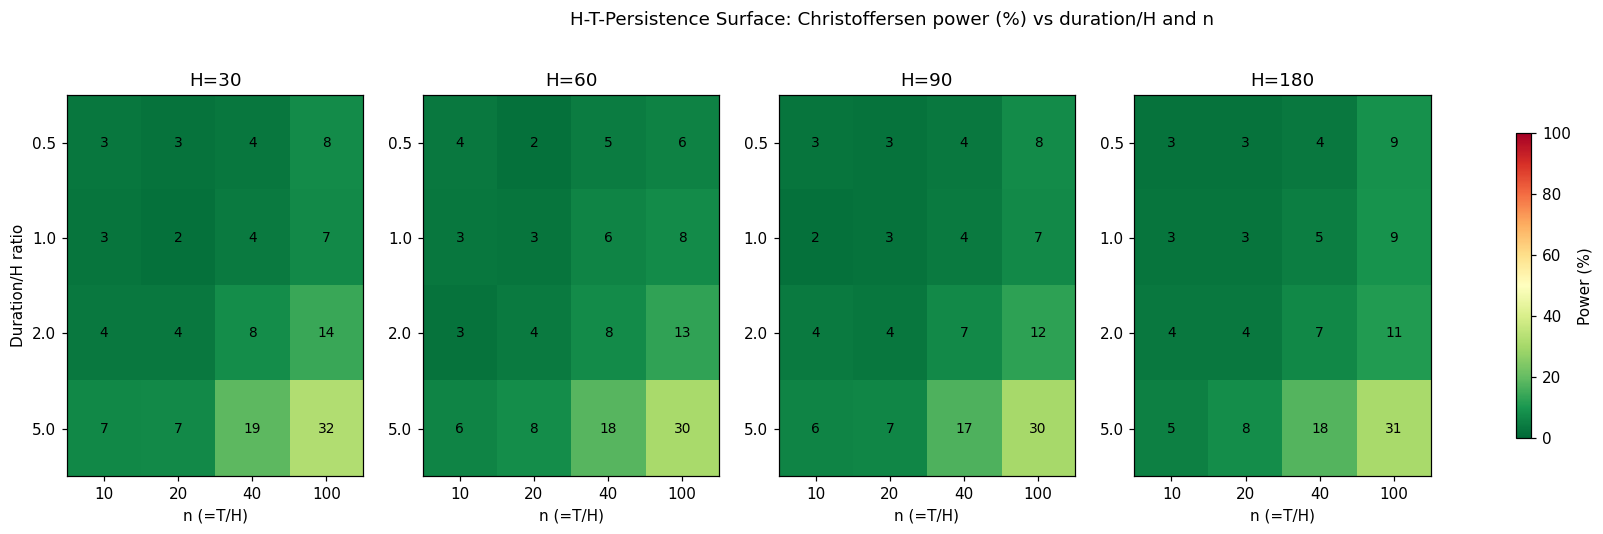

Saved: HT_surface.png


In [20]:
# Heatmap: averaged over H (to show the ratio x n pattern), and per H individually
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for hi, H_ in enumerate(H_grid):
    ax = axes[hi]
    im = ax.imshow(surface[hi], cmap='RdYlGn_r', vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(len(n_grid)))
    ax.set_xticklabels(n_grid)
    ax.set_yticks(range(len(ratio_grid)))
    ax.set_yticklabels(ratio_grid)
    ax.set_xlabel('n (=T/H)')
    ax.set_ylabel('Duration/H ratio' if hi == 0 else '')
    ax.set_title(f'H={H_}')
    for ri in range(len(ratio_grid)):
        for ni in range(len(n_grid)):
            ax.text(ni, ri, f'{surface[hi, ri, ni]:.0f}', ha='center', va='center', fontsize=9)
fig.colorbar(im, ax=axes, label='Power (%)', shrink=0.8)
plt.suptitle('H-T-Persistence Surface: Christoffersen power (%) vs duration/H and n', y=1.05)
plt.savefig('HT_surface.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: HT_surface.png')


---
## Table 6: Extreme Quantiles (95% and 99% Value-at-Risk)

The main design (Tables 1-5) uses 80% intervals. This section repeats the size and power checks
at 95% and 99% coverage, the levels used in banking and insurance regulation.

Power is measured against one continuous two-state Markov regime (persistence 0.98) cut into
non-overlapping blocks, the Experiment B design.

In [21]:
rng_table6 = np.random.default_rng(SEED)
REPS_T6 = effective_reps(1000)
print(f'Parameters fixed: H={H}, REPS={REPS_T6}, seed={SEED}, coverage levels 80/95/99%')


Parameters fixed: H=90, REPS=1000, seed=42, coverage levels 80/95/99%


In [22]:
print('Table 6: Size (daily) and Power (n=34, n=500) across coverage levels \n')
print(f"{'Coverage':>10} {'Kupiec size(%)':>15} {'Christ size(%)':>15} {'Christ pow n=34(%)':>19} {'Kupiec pow n=34(%)':>19} {'Christ pow n=500(%)':>20}")

results_t6 = {}
for cov_pct, alpha in tqdm([(80, 0.20), (95, 0.05), (99, 0.01)], desc='Table 6'):
    V_daily = gen_size_daily(rng_table6, 2000, H, alpha, reps=REPS_T6)
    kup_size = (kupiec_stat(V_daily, alpha) < 0.05).mean() * 100
    christ_size = (christ_stat(V_daily, alpha) < 0.05).mean() * 100

    V34 = gen_experimentB_alpha(rng_table6, H, 34, alpha, reps=REPS_T6)
    christ_pow34 = (christ_stat(V34, alpha) < 0.05).mean() * 100
    kup_pow34 = (kupiec_stat(V34, alpha) < 0.05).mean() * 100

    V500 = gen_experimentB_alpha(rng_table6, H, 500, alpha, reps=REPS_T6)
    christ_pow500 = (christ_stat(V500, alpha) < 0.05).mean() * 100

    results_t6[cov_pct] = (kup_size, christ_size, christ_pow34, kup_pow34, christ_pow500)
    print(f'{cov_pct:>9}% {kup_size:>15.1f} {christ_size:>15.1f} {christ_pow34:>19.1f} {kup_pow34:>19.1f} {christ_pow500:>20.1f}')


Table 6: Size (daily) and Power (n=34, n=500) across coverage levels 

  Coverage  Kupiec size(%)  Christ size(%)  Christ pow n=34(%)  Kupiec pow n=34(%)  Christ pow n=500(%)


Table 6:  33%|███████████▋                       | 1/3 [00:01<00:03,  1.72s/it]

       80%            79.0           100.0                 3.5                 5.6                  4.8


Table 6:  67%|███████████████████████▎           | 2/3 [00:03<00:01,  1.72s/it]

       95%            75.5            99.6                 2.0                 3.1                  4.6


Table 6: 100%|███████████████████████████████████| 3/3 [00:05<00:00,  1.71s/it]

       99%            56.4            79.1                 1.7                 5.3                  1.3


---
## Table 8: Self-Normalized Coverage Tests

This is not a reproduction of the Chen and Lai (2026) statistic. It applies the general
self-normalization idea (Lobato 2001; Kiefer, Vogelsang and Bunzel 2000; Shao 2010) to coverage testing.

**Definitions.** Let `d_t` be the series being tested, `d_bar` its mean over `n` observations, and
`S_k = sum_{t<=k} (d_t - d_bar)` its centred partial sums. The statistic is

    T_n = sqrt(n) * d_bar / sqrt( (1/n) * sum_k S_k^2 )

The code divides the sum of squared partial sums by `n`. Some papers divide by `n^2`. The two
versions differ only by a constant factor, which the simulated critical values absorb, so the
test is the same.

- **SN unconditional test:** `d_t = V_t - alpha`. Tests that the violation rate equals alpha (analogue of Kupiec).
- **SN independence test:** `d_t = (V_t - alpha)(V_{t-1} - alpha)`. Tests lag-1 dependence (analogue of Christoffersen).

Critical values of `|T_n|` are simulated for each `n` under i.i.d. Bernoulli(alpha) violations.
The statistic needs no bandwidth.

In [23]:
print('Example critical-value calibration for n=30, 60, 90:')
for n_test in [30, 60, 90]:
    cv = get_sn_critical_value(rng, n_test)
    print(f'  n={n_test}: critical value |T_n| = {cv:.3f} (for comparison: normal 1.96)')

Example critical-value calibration for n=30, 60, 90:
  n=30: critical value |T_n| = 1.322 (for comparison: normal 1.96)
  n=60: critical value |T_n| = 0.912 (for comparison: normal 1.96)
  n=90: critical value |T_n| = 0.728 (for comparison: normal 1.96)


In [24]:
# SIZE check for SN tests (correctly calibrated data, as in Table 1)
H_sn = 90
print('SIZE: SN tests vs classical tests (correctly calibrated, H=90)\n')
print(f"{'s':>4} {'n':>5} {'SN-uncond rej(%)':>17} {'SN-indep rej(%)':>16} {'(cf. Kupiec/Christoffersen from Table 1)':>10}")
cv_cache = {}
for s in [1, 30, 60, 90]:
    V = gen_size_sliding(rng, 2000, H_sn, s)
    rej_u = sn_unconditional_test(rng, V, cv_cache=cv_cache).mean() * 100
    rej_i = sn_independence_test(rng, V, cv_cache=cv_cache).mean() * 100
    print(f'{s:>4} {V.shape[1]:>5} {rej_u:>17.1f} {rej_i:>16.1f}')


SIZE: SN tests vs classical tests (correctly calibrated, H=90)

   s     n  SN-uncond rej(%)  SN-indep rej(%) (cf. Kupiec/Christoffersen from Table 1)
   1  2000               6.8             92.8
  30    67               6.0             28.7
  60    34               5.5              4.1
  90    23               5.5              4.9


In [25]:
# POWER: SN-independence test against genuine clustering (cf. Table 2) 
print('POWER: SN-independence test vs Christoffersen (genuine clustering, H=90) \n')
print(f"{'s':>4} {'n':>5} {'SN-indep power(%)':>18} {'Christoffersen power(%)':>24}")
cv_cache2 = {}
for s in [30, 60, 90]:
    V = gen_clustered_sliding(rng, 2000, 90, s, reps=2000)
    p_sn = sn_independence_test(rng, V, cv_cache=cv_cache2).mean() * 100
    p_christ = (christ_stat(V) < 0.05).mean() * 100
    print(f'{s:>4} {V.shape[1]:>5} {p_sn:>18.1f} {p_christ:>24.1f}')

POWER: SN-independence test vs Christoffersen (genuine clustering, H=90) 

   s     n  SN-indep power(%)  Christoffersen power(%)
  30    67               37.9                     65.0
  60    34                6.1                      6.7
  90    23                4.9                      3.5
